# 03 — Baseline econometric models

**Scope:** B0 Gaussian constant variance; B1 Gaussian GARCH(1,1); M1 two-state and M2 three-state Gaussian Markov switching with constant transition probabilities. No GPR/VIX transition model or out-of-sample evaluation is estimated.

The comparison uses **exactly the 3,699 complete-case Brent training returns** (4 January 2000–31 December 2015), in percentage points. Validation and test observations remain in the loaded file but are never passed to estimators or preprocessing. All lag indices refer to retained observations rather than calendar days. Results are in-sample descriptions of latent statistical states, not observed true regimes.

## 1. Input and reproducibility checks

This notebook reads Notebook 01's processed Brent complete-case file. It stops if its columns, dates, split counts, or return validity have changed. Packages and optimizer settings are recorded. The three Markov starts are seeded at 41, 67, and 103, each with 10 EM iterations, 8 random search repetitions of 8 iterations, and up to 300 optimizer iterations. The best *converged, finite, positive-variance* solution is retained. Failed and warning-producing attempts remain in the exported attempt log.

In [1]:
from pathlib import Path
import platform, warnings
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt
import scipy, statsmodels, arch
from scipy.special import logsumexp
from scipy.stats import norm
from arch import arch_model
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from IPython.display import display, Markdown

PROJECT=Path.cwd() if (Path.cwd()/"data"/"processed").is_dir() else Path.cwd().parent
DATA=PROJECT/"data"/"processed"
TABLES=PROJECT/"results"/"tables"
FIGURES=PROJECT/"results"/"figures"
source=DATA/"01_brent_complete_case.csv"
assert source.exists(), source
df=pd.read_csv(source,parse_dates=["date","previous_observed_date","vix_lag_source_date"])
needed={"date","split","brent_return_pct","gpr_index","vix_index",
        "gpr_lag1_calendar_day","vix_lag1_observation"}
assert needed.issubset(df.columns), needed-set(df.columns)
assert len(df)==6410 and df.date.is_unique and df.date.is_monotonic_increasing
assert df.date.min()==pd.Timestamp("2000-01-04")
assert df.date.max()==pd.Timestamp("2026-10-26")
assert df[["date","split","brent_return_pct"]].notna().all().all()
assert df[["gpr_index","vix_index","gpr_lag1_calendar_day",
           "vix_lag1_observation"]].notna().all().all()
split=np.select([df.date.le("2015-12-31"),df.date.le("2019-12-31")],
                ["train","validation"],default="test")
assert np.array_equal(df.split.to_numpy(),split)
assert df.split.value_counts().to_dict()=={"train":3699,"validation":999,"test":1712}
train=df.loc[df.split.eq("train")].copy().reset_index(drop=True)
assert train.date.max()<=pd.Timestamp("2015-12-31")
y=train.brent_return_pct.to_numpy(dtype=float)
assert np.isfinite(y).all() and len(y)==3699
dates=train.date
TABLES.mkdir(parents=True,exist_ok=True)
FIGURES.mkdir(parents=True,exist_ok=True)
display(pd.DataFrame({"split":["train","validation","test"],
                      "observations":[3699,999,1712]}))
display(pd.Series({"Python":platform.python_version(),"NumPy":np.__version__,
                   "pandas":pd.__version__,"SciPy":scipy.__version__,
                   "statsmodels":statsmodels.__version__,"arch":arch.__version__,
                   "Matplotlib":matplotlib.__version__},name="version").to_frame())
plt.rcParams.update({"figure.dpi":110,"savefig.dpi":180,"font.size":10,
                     "axes.spines.top":False,"axes.spines.right":False})

,split,observations
0,train,3699
1,validation,999
2,test,1712


,version
Python,3.12.14
NumPy,2.5.4
pandas,3.0.1
SciPy,1.18.1
statsmodels,0.15.0
arch,8.0.0
Matplotlib,3.11.2


## 2. B0: constant mean and variance

The benchmark assumes \(r_t\overset{iid}{\sim}N(\mu,\sigma^2)\). Maximum likelihood gives the sample mean and variance with divisor \(n\), distinct from the descriptive sample variance with divisor \(n-1\). It has two free parameters. We compute the Gaussian log likelihood directly and verify it against the sum of normal log densities.

In [2]:
n=len(y)
b0_mu=float(y.mean())
b0_var=float(np.mean((y-b0_mu)**2))
b0_sd=float(np.sqrt(b0_var))
b0_ll=float(np.sum(norm.logpdf(y,loc=b0_mu,scale=b0_sd)))
b0_check=float(-.5*n*(np.log(2*np.pi*b0_var)+1))
assert np.isclose(b0_ll,b0_check)
b0={"mu":b0_mu,"sigma2":b0_var,"sigma":b0_sd,
    "log_likelihood":b0_ll,"aic":-2*b0_ll+2*2,
    "bic":-2*b0_ll+2*np.log(n)}
display(pd.Series(b0,name="B0").to_frame())
pd.Series(b0,name="value").to_csv(TABLES/"03_b0_parameters.csv")

,B0
mu,0.009490
sigma2,5.503410
sigma,2.345935
log_likelihood,-8402.731716
aic,16809.463433
bic,16821.895069


## 3. B1: Gaussian GARCH(1,1)

Here \(r_t=\mu+\epsilon_t\), \(\epsilon_t=\sigma_t z_t\), \(z_t\sim N(0,1)\), and \(\sigma_t^2=\omega+\alpha\epsilon_{t-1}^2+\beta\sigma_{t-1}^2\). Omega is the variance intercept, alpha reacts to the latest squared shock, and beta carries forward prior conditional variance. We disable automatic rescaling so the fitted input remains in percentage points. The package initializes the variance recursion internally; its likelihood convention differs from Markov filtering initialization, so cross-family AIC/BIC comparisons need care. A higher likelihood by itself does not establish adequate residual behavior.

,parameter,estimate,std_error,t_stat,p_value
0,mu,0.02060,0.02952,0.69799,0.48519
1,omega,0.01147,0.00649,1.76627,0.07735
2,alpha[1],0.04896,0.01007,4.86261,0.00000
3,beta[1],0.95104,0.00910,104.55066,0.00000


,B1
log_likelihood,-7943.74985
aic,15895.499699
bic,15920.362971
convergence_flag,0
converged,True
alpha_plus_beta,1.0
omega_positive,True
alpha_nonnegative,True
beta_nonnegative,True
alpha_plus_beta_lt_1,True


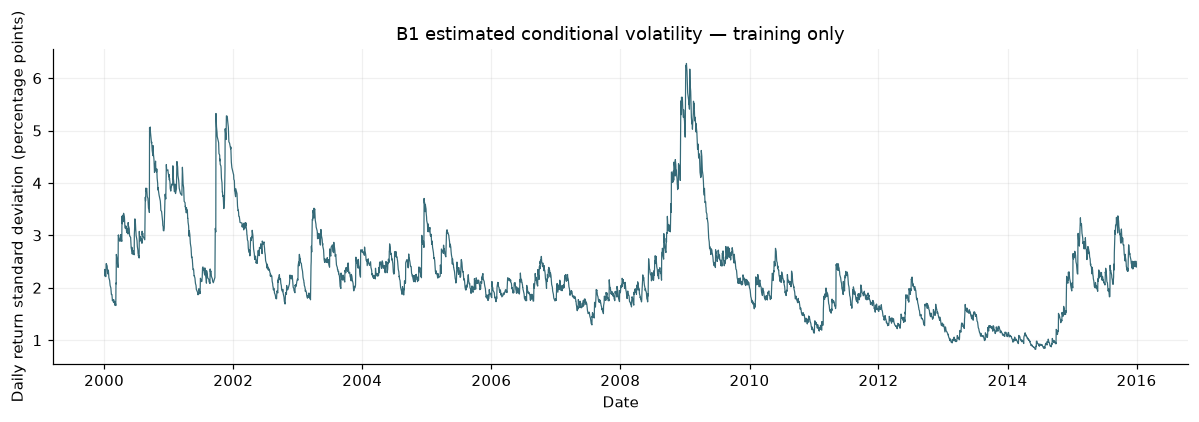

In [3]:
garch=arch_model(y,mean="Constant",vol="GARCH",p=1,o=0,q=1,
                 dist="normal",rescale=False).fit(disp="off",show_warning=False,
                                                   options={"maxiter":1000})
gp=garch.params
garch_rows=pd.DataFrame({"parameter":gp.index,"estimate":gp.values,
                         "std_error":garch.std_err.values,"t_stat":garch.tvalues.values,
                         "p_value":garch.pvalues.values})
garch_rows.to_csv(TABLES/"03_garch_parameters.csv",index=False,float_format="%.10g")
display(garch_rows.round(5))
garch_persistence=float(gp["alpha[1]"]+gp["beta[1]"])
garch_near_unit=bool(garch_persistence>=0.995)
garch_converged=(garch.convergence_flag==0)
garch_conditions={"omega_positive":bool(gp["omega"]>0),
                  "alpha_nonnegative":bool(gp["alpha[1]"]>=0),
                  "beta_nonnegative":bool(gp["beta[1]"]>=0),
                  "alpha_plus_beta_lt_1":bool(garch_persistence<1),
                  "near_unit_persistence":garch_near_unit}
display(pd.Series({"log_likelihood":garch.loglikelihood,"aic":garch.aic,
                   "bic":garch.bic,"convergence_flag":garch.convergence_flag,
                   "converged":garch_converged,"alpha_plus_beta":garch_persistence,
                   **garch_conditions},name="B1").to_frame())
pd.Series({"log_likelihood":garch.loglikelihood,"aic":garch.aic,
           "bic":garch.bic,"convergence_flag":garch.convergence_flag,
           "alpha_plus_beta":garch_persistence,**garch_conditions},
          name="value").to_csv(TABLES/"03_garch_diagnostics.csv")
assert len(garch.conditional_volatility)==n
fig,ax=plt.subplots(figsize=(11,3.8))
ax.plot(dates,garch.conditional_volatility,lw=.8,color="#356a78")
ax.set(title="B1 estimated conditional volatility — training only",
       xlabel="Date",ylabel="Daily return standard deviation (percentage points)")
ax.grid(alpha=.18);fig.tight_layout()
fig.savefig(FIGURES/"03_garch_conditional_volatility.png",bbox_inches="tight")
plt.show()

### B1 standardized residual checks

We divide demeaned returns by estimated conditional standard deviation. Ljung–Box tests at 5, 10, and 20 lags inspect remaining serial correlation in standardized residuals and their squares; ARCH-LM with 10 lags checks remaining conditional heteroskedasticity. These diagnostics use training observations and do not treat in-sample likelihood alone as adequacy evidence.

In [4]:
z=np.asarray(garch.std_resid,dtype=float)
assert len(z)==n and np.isfinite(z).all()
resid_rows=[]
for series,values in [("standardized residual",z),
                      ("squared standardized residual",z**2)]:
    lb=acorr_ljungbox(values,lags=[5,10,20],return_df=True,model_df=0)
    for lag,row in lb.iterrows():
        resid_rows.append({"series":series,"test":"Ljung-Box","lags":lag,
                           "statistic":row.lb_stat,"p_value":row.lb_pvalue})
lm,lmp,_,_=het_arch(z-z.mean(),nlags=10,ddof=1,result_object=False)
resid_rows.append({"series":"standardized residual","test":"ARCH-LM",
                   "lags":10,"statistic":lm,"p_value":lmp})
resid_tests=pd.DataFrame(resid_rows)
display(resid_tests.round(6))
resid_tests.to_csv(TABLES/"03_garch_residual_tests.csv",index=False,float_format="%.10g")

,series,test,lags,statistic,p_value
0,standardized residual,Ljung-Box,5,8.104793,0.150554
1,standardized residual,Ljung-Box,10,11.597110,0.312925
2,standardized residual,Ljung-Box,20,27.608074,0.119007
3,squared standardized residual,Ljung-Box,5,29.697130,0.000017
4,squared standardized residual,Ljung-Box,10,33.548662,0.000220
5,squared standardized residual,Ljung-Box,20,48.135092,0.000407
6,standardized residual,ARCH-LM,10,35.110672,0.000120


## 4. M1 and M2: Gaussian Markov switching

Conditional on latent state \(S_t=j\), returns follow \(N(\mu_j,\sigma_j^2)\). State changes follow a constant first-order transition matrix. Both mean and variance switch. Three seeded multi-start optimizations are attempted per model; the highest valid converged log likelihood is retained. This reduces but cannot eliminate local-optimum risk.

The statsmodels transition tensor uses destination rows and origin columns: element [j,i,t] is the probability of state j at t given state i at t-1. We transpose it to a conventional table with origin rows and destination columns, then reorder by increasing estimated variance. Expected duration is 1/(1-p_ii) retained observations. Filtered probabilities use observations through t; smoothed probabilities also use later training observations and are retrospective only.

Implementation references: [statsmodels Markov switching example](https://www.statsmodels.org/stable/examples/notebooks/generated/markov_regression.html) and [arch GARCH formulation](https://arch.readthedocs.io/en/stable/univariate/introduction.html).

In [5]:
SEEDS=[41,67,103]
FIT_SETTINGS={"em_iter":10,"search_reps":8,"search_iter":8,
              "maxiter":300,"disp":False}
attempts=[]
fits={}
for k in [2,3]:
    model=MarkovRegression(y,k_regimes=k,trend="c",
                           switching_trend=True,switching_variance=True)
    candidates=[]
    for seed in SEEDS:
        np.random.seed(seed)
        try:
            with warnings.catch_warnings(record=True) as caught:
                warnings.simplefilter("always")
                res=model.fit(**FIT_SETTINGS)
            params=pd.Series(res.params,index=res.model.param_names)
            variances=np.array([params[f"sigma2[{j}]"] for j in range(k)])
            finite=bool(np.isfinite(res.llf) and np.isfinite(res.params).all())
            converged=bool(res.mle_retvals.get("converged",False))
            positive=bool(np.all(variances>0))
            warnings_text=" | ".join(f"{w.category.__name__}: {w.message}" for w in caught)
            attempts.append({"model":f"M{k-1}","states":k,"seed":seed,
                             "log_likelihood":res.llf,"converged":converged,
                             "finite":finite,"positive_variances":positive,
                             "iterations":res.mle_retvals.get("iterations",np.nan),
                             "warning_count":len(caught),"warnings":warnings_text,
                             "error":""})
            if converged and finite and positive:
                candidates.append((res.llf,seed,res))
        except Exception as exc:
            attempts.append({"model":f"M{k-1}","states":k,"seed":seed,
                             "log_likelihood":np.nan,"converged":False,
                             "finite":False,"positive_variances":False,
                             "iterations":np.nan,"warning_count":0,"warnings":"",
                             "error":repr(exc)})
    if candidates:
        fits[k]=max(candidates,key=lambda item:item[0])

attempt_table=pd.DataFrame(attempts)
display(attempt_table[["model","seed","log_likelihood","converged",
                       "positive_variances","warning_count","error"]].round(4))
attempt_table.to_csv(TABLES/"03_markov_attempts.csv",index=False,float_format="%.10g")
if 2 not in fits:
    raise RuntimeError("M1 has no valid converged solution; inspect attempt log")
if 3 not in fits:
    print("M2 has no valid converged solution; instability is retained in the attempt log.")

def regime_summary(k,fit):
    ll,seed,res=fit
    p=pd.Series(res.params,index=res.model.param_names)
    order=np.argsort([p[f"sigma2[{j}]"] for j in range(k)])
    labels=["Low","High"] if k==2 else ["Low","Medium","High"]
    raw=np.asarray(res.regime_transition)
    assert raw.shape==(k,k,1), f"Unexpected transition tensor: {raw.shape}"
    assert np.allclose(raw[:,:,0].sum(axis=0),1,atol=1e-8)
    transition=raw[:,:,0].T[np.ix_(order,order)]
    assert np.allclose(transition.sum(axis=1),1,atol=1e-8)
    assert np.all(transition>=-1e-8) and np.all(transition<=1+1e-8)
    filtered=np.asarray(res.filtered_marginal_probabilities)[:,order]
    smoothed=np.asarray(res.smoothed_marginal_probabilities)[:,order]
    assert filtered.shape==smoothed.shape==(n,k)
    assert np.allclose(filtered.sum(axis=1),1,atol=1e-6)
    assert np.allclose(smoothed.sum(axis=1),1,atol=1e-6)
    classed=np.argmax(smoothed,axis=1)
    rows=[]
    for rank,original in enumerate(order):
        variance=float(p[f"sigma2[{original}]"])
        diagonal=float(transition[rank,rank])
        rows.append({"state":rank,"label":labels[rank],
                     "original_statsmodels_state":int(original),
                     "mean_pct":float(p[f"const[{original}]"]),
                     "variance_pct2":variance,"sd_pct":np.sqrt(variance),
                     "stay_probability":diagonal,
                     "expected_duration_observations":1/(1-diagonal),
                     "mean_smoothed_occupancy":smoothed[:,rank].mean(),
                     "most_likely_smoothed_days":int((classed==rank).sum()),
                     "mean_filtered_occupancy":filtered[:,rank].mean()})
    summary=pd.DataFrame(rows)
    matrix=pd.DataFrame(transition,index=[f"{lab} origin" for lab in labels],
                        columns=[f"{lab} destination" for lab in labels])
    probabilities=pd.DataFrame({"date":dates})
    for j,lab in enumerate(labels):
        probabilities[f"filtered_{lab.lower()}"]=filtered[:,j]
        probabilities[f"smoothed_{lab.lower()}"]=smoothed[:,j]
    stem=f"03_m{k-1}"
    summary.to_csv(TABLES/f"{stem}_regimes.csv",index=False,float_format="%.10g")
    matrix.to_csv(TABLES/f"{stem}_transition_matrix.csv",float_format="%.10g")
    probabilities.to_csv(TABLES/f"{stem}_probabilities.csv",index=False,
                         date_format="%Y-%m-%d",float_format="%.10g")
    pd.DataFrame({"parameter":p.index,"estimate":p.values,
                  "std_error":np.asarray(res.bse)}).to_csv(
                      TABLES/f"{stem}_parameters.csv",index=False,float_format="%.10g")
    return {"result":res,"seed":seed,"summary":summary,"matrix":matrix,
            "filtered":filtered,"smoothed":smoothed,"labels":labels}

markov={k:regime_summary(k,fit) for k,fit in fits.items()}
for k,item in markov.items():
    print(f"M{k-1}: chosen seed {item['seed']}; log likelihood {item['result'].llf:.4f}")
    display(item["summary"].round(4))
    display(item["matrix"].round(4))

,model,seed,log_likelihood,converged,positive_variances,warning_count,error
0,M1,41,-8042.6257,True,True,0,
1,M1,67,-8042.6257,True,True,0,
2,M1,103,-8042.6257,True,True,0,
3,M2,41,-7903.8206,True,True,0,
4,M2,67,-7903.8209,True,True,0,
5,M2,103,-7903.8215,True,True,0,


M1: chosen seed 67; log likelihood -8042.6257


,state,label,original_statsmodels_state,mean_pct,variance_pct2,sd_pct,stay_probability,expected_duration_observations,mean_smoothed_occupancy,most_likely_smoothed_days,mean_filtered_occupancy
0,0,Low,0,0.1224,2.4794,1.5746,0.9734,37.6183,0.6819,2585,0.6881
1,1,High,1,-0.2325,11.8987,3.4495,0.9436,17.7353,0.3181,1114,0.3119


,Low destination,High destination
Low origin,0.9734,0.0266
High origin,0.0564,0.9436


M2: chosen seed 41; log likelihood -7903.8206


,state,label,original_statsmodels_state,mean_pct,variance_pct2,sd_pct,stay_probability,expected_duration_observations,mean_smoothed_occupancy,most_likely_smoothed_days,mean_filtered_occupancy
0,0,Low,0,0.0482,1.1132,1.0551,0.9862,72.6970,0.2090,751,0.2125
1,1,Medium,1,0.0714,4.3979,2.0971,0.9895,95.2273,0.6786,2562,0.6747
2,2,High,2,-0.4352,20.1160,4.4851,0.9608,25.5115,0.1124,386,0.1128


,Low destination,Medium destination,High destination
Low origin,0.9862,0.0138,0.0000
Medium origin,0.0041,0.9895,0.0064
High origin,0.0000,0.0392,0.9608


### Markov state plots and stability checks

M1 high-volatility filtered and smoothed probabilities are shown separately. M2 shows all three smoothed probabilities; its filtered probabilities and the full daily series are exported. The return overlay compares large moves with retrospective state assignments. Historical event correspondence is descriptive and does not validate state-detection accuracy.

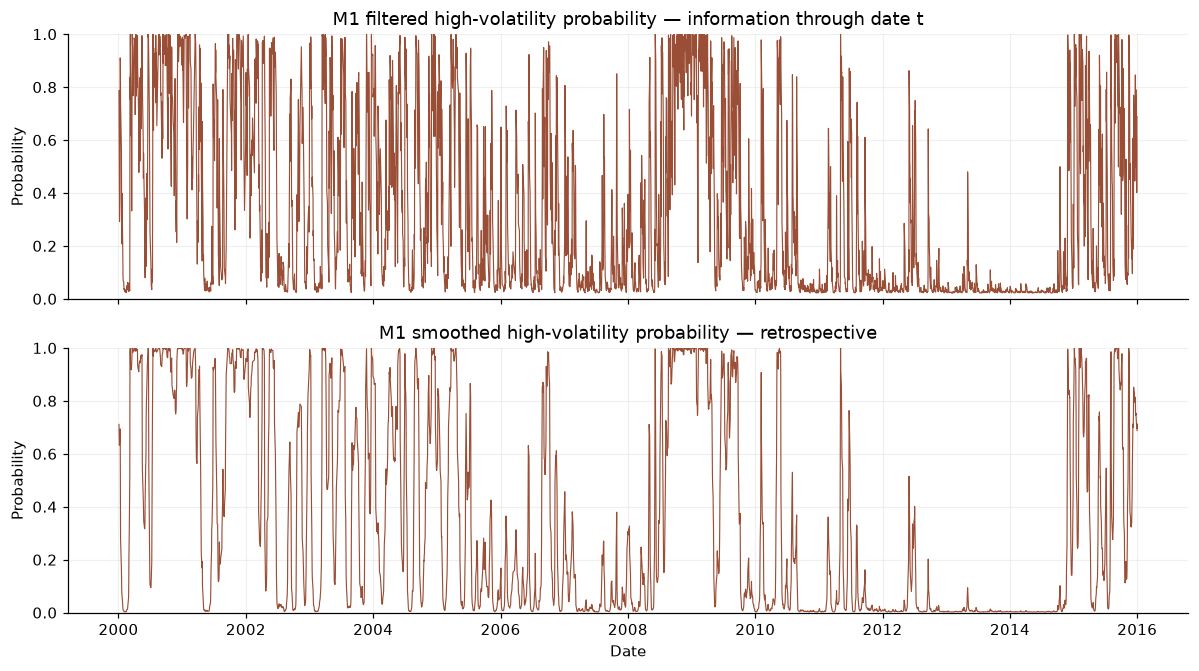

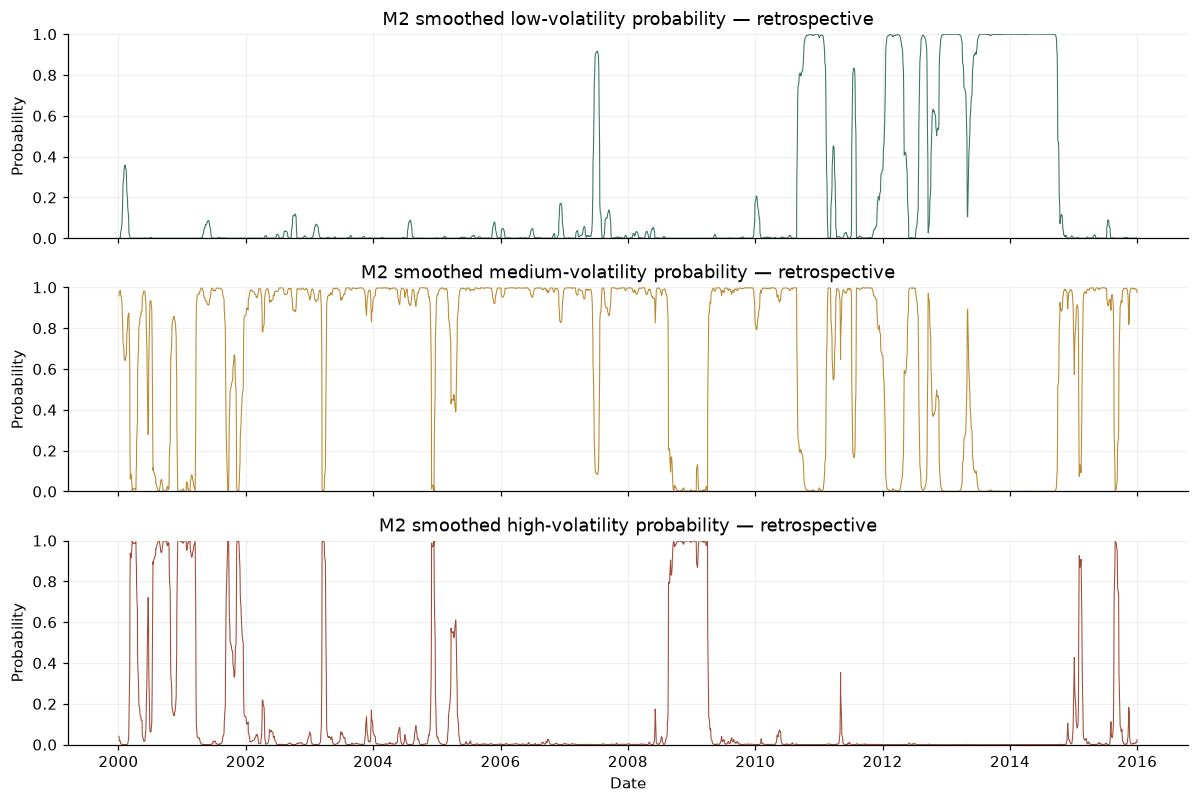

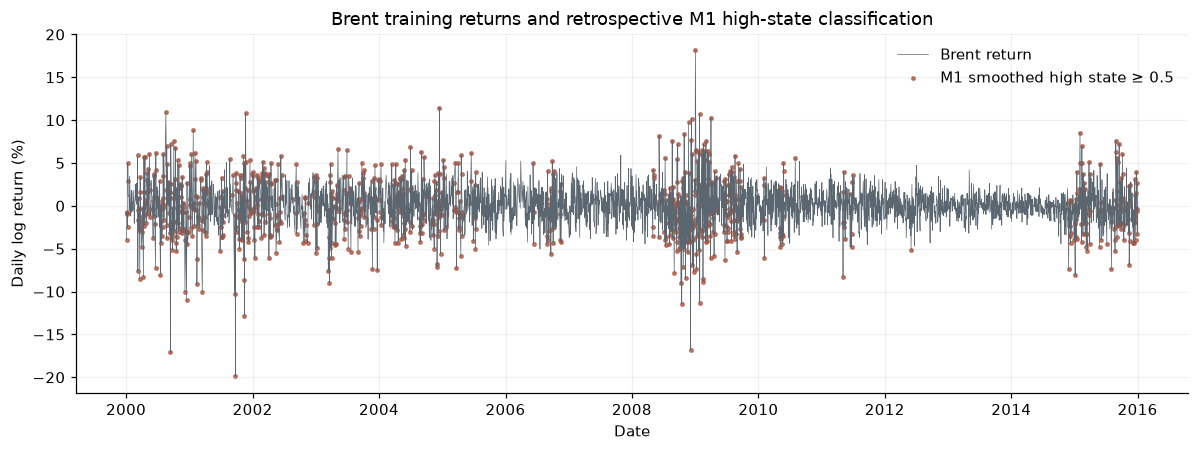

In [6]:
m1=markov[2]
fig,axes=plt.subplots(2,1,figsize=(11,6.2),sharex=True)
axes[0].plot(dates,m1["filtered"][:,1],lw=.75,color="#9a4e36")
axes[0].set(title="M1 filtered high-volatility probability — information through date t",
            ylabel="Probability",ylim=(0,1))
axes[1].plot(dates,m1["smoothed"][:,1],lw=.75,color="#9a4e36")
axes[1].set(title="M1 smoothed high-volatility probability — retrospective",
            xlabel="Date",ylabel="Probability",ylim=(0,1))
for ax in axes: ax.grid(alpha=.18)
fig.tight_layout()
fig.savefig(FIGURES/"03_m1_probabilities.png",bbox_inches="tight")
plt.show()

if 3 in markov:
    m2=markov[3]
    fig,axes=plt.subplots(3,1,figsize=(11,7.4),sharex=True)
    colors=["#397566","#ba8a30","#a14c3a"]
    for j,(ax,lab) in enumerate(zip(axes,m2["labels"])):
        ax.plot(dates,m2["smoothed"][:,j],lw=.7,color=colors[j])
        ax.set(title=f"M2 smoothed {lab.lower()}-volatility probability — retrospective",
               ylabel="Probability",ylim=(0,1))
        ax.grid(alpha=.18)
    axes[-1].set_xlabel("Date")
    fig.tight_layout()
    fig.savefig(FIGURES/"03_m2_probabilities.png",bbox_inches="tight")
    plt.show()

fig,ax=plt.subplots(figsize=(11,4.2))
ax.plot(dates,y,lw=.45,color="#5a6670",label="Brent return")
ax.scatter(dates,np.where(m1["smoothed"][:,1]>=.5,y,np.nan),
           s=5,color="#ac4f39",alpha=.7,label="M1 smoothed high state ≥ 0.5")
ax.set(title="Brent training returns and retrospective M1 high-state classification",
       xlabel="Date",ylabel="Daily log return (%)")
ax.legend(frameon=False,loc="upper right")
ax.grid(alpha=.18);fig.tight_layout()
fig.savefig(FIGURES/"03_returns_m1_classification.png",bbox_inches="tight")
plt.show()

## 5. Identical-sample comparison and interpretation

All four model likelihoods use the same 3,699 observed returns. B0 has 2 free parameters, B1 has 4, M1 has 6, and M2 has 12. AIC and BIC penalize parameter count. Their numerical comparison across GARCH and Markov implementations is descriptive because likelihood initialization differs: GARCH initializes its variance recursion, while Markov likelihood evaluation initializes state probabilities. The table does not determine a forecasting winner. M1 versus M2 also needs variance separation, state occupancy, persistence, convergence, and boundary checks; a favorable criterion alone is insufficient.

In [7]:
rows=[{"model":"B0 Gaussian constant variance","parameters":2,"training_observations":n,
       "log_likelihood":b0_ll,"aic":b0["aic"],"bic":b0["bic"],
       "converged":True,"chosen_seed":np.nan},
      {"model":"B1 Gaussian GARCH(1,1)","parameters":len(garch.params),
       "training_observations":n,"log_likelihood":garch.loglikelihood,
       "aic":garch.aic,"bic":garch.bic,"converged":garch_converged,
       "chosen_seed":np.nan}]
for k in [2,3]:
    if k in markov:
        item=markov[k]; res=item["result"]
        rows.append({"model":f"M{k-1} Gaussian {k}-state Markov",
                     "parameters":len(res.params),"training_observations":n,
                     "log_likelihood":res.llf,"aic":res.aic,"bic":res.bic,
                     "converged":bool(res.mle_retvals.get("converged",False)),
                     "chosen_seed":item["seed"]})
    else:
        rows.append({"model":f"M{k-1} Gaussian {k}-state Markov",
                     "parameters":k*k+k,"training_observations":n,
                     "log_likelihood":np.nan,"aic":np.nan,"bic":np.nan,
                     "converged":False,"chosen_seed":np.nan})
comparison=pd.DataFrame(rows)
assert comparison.training_observations.eq(n).all()
display(comparison.round(3))
comparison.to_csv(TABLES/"03_model_comparison.csv",index=False,float_format="%.10g")

stability_rows=[]
for k,item in markov.items():
    s=item["summary"]
    valid=attempt_table.loc[(attempt_table.states==k)&attempt_table.converged&
                            attempt_table.finite&attempt_table.positive_variances]
    spread=float(valid.log_likelihood.max()-valid.log_likelihood.min())
    min_occupancy=float(s.mean_smoothed_occupancy.min())
    ratio=float(s.variance_pct2.max()/s.variance_pct2.min())
    min_transition=float(item["matrix"].to_numpy().min())
    missing_se=int(pd.isna(np.asarray(item["result"].bse)).sum())
    stability_rows.append({"model":f"M{k-1}","successful_starts":len(valid),
                           "attempted_starts":len(SEEDS),
                           "loglikelihood_spread":spread,
                           "min_mean_smoothed_occupancy":min_occupancy,
                           "variance_max_min_ratio":ratio,
                           "minimum_transition_probability":min_transition,
                           "near_boundary_transition":min_transition<1e-5,
                           "tiny_variance":bool(s.variance_pct2.min()<.05),
                           "unavailable_standard_errors":missing_se})
stability=pd.DataFrame(stability_rows)
display(stability.round(5))
stability.to_csv(TABLES/"03_markov_stability.csv",index=False,float_format="%.10g")

def test_p(series,test,lag):
    z=resid_tests.loc[(resid_tests.series==series)&(resid_tests.test==test)&
                      (resid_tests.lags==lag),"p_value"]
    assert len(z)==1
    return float(z.iloc[0])

m1s=markov[2]["summary"]
m1_high=m1s.loc[m1s.label.eq("High")].iloc[0]
garch_squared_lb=test_p("squared standardized residual","Ljung-Box",10)
garch_arch=test_p("standardized residual","ARCH-LM",10)
if 3 in markov:
    m2s=markov[3]["summary"]
    m2_extra=(f"M2 separates low/medium/high daily standard deviations of "
              f"{m2s.sd_pct.iloc[0]:.2f}, {m2s.sd_pct.iloc[1]:.2f}, and "
              f"{m2s.sd_pct.iloc[2]:.2f} percentage points; its smallest mean "
              f"smoothed occupancy is {m2s.mean_smoothed_occupancy.min():.1%}. "
              f"The near-zero direct high-to-low transition estimate is a boundary "
              f"warning, and {int(stability.loc[stability.model.eq('M2'),'unavailable_standard_errors'].iloc[0])} transition standard error(s) are unavailable, even "
              f"though all seeded starts converged.")
else:
    m2_extra="M2 did not yield a valid converged fit; inspect the attempt log before drawing a three-state conclusion."
findings=f'''
### Findings from the training sample

1. **M1 regimes:** Its low and high daily standard deviations are {m1s.sd_pct.iloc[0]:.2f} and {m1s.sd_pct.iloc[1]:.2f} percentage points. The high state has mean smoothed occupancy {m1_high.mean_smoothed_occupancy:.1%}. Large training-sample returns, notably around 2008–09, often coincide with high retrospective probabilities. This is an economically interpretable visual correspondence rather than proof of true regimes or a formal event test.
2. **Persistence:** M1 expected durations are {m1s.expected_duration_observations.iloc[0]:.1f} and {m1s.expected_duration_observations.iloc[1]:.1f} retained observations for low and high states. These are not calendar days.
3. **Additional state:** {m2_extra}
4. **Fit versus GARCH:** B1 log likelihood is {garch.loglikelihood:.1f}; M1 is {markov[2]["result"].llf:.1f}''' + (f'''; M2 is {markov[3]["result"].llf:.1f}''' if 3 in markov else "") + f'''. See the comparison table for AIC/BIC and initialization caveats. In-sample fit does not establish forecasting superiority.
5. **Numerical and economic caution:** GARCH alpha+beta is {garch_persistence:.9f}, effectively at the unit-persistence boundary. Although the unrounded estimate is just below one, a finite and well-determined unconditional variance should not be asserted from this point estimate. The 10-lag squared-standardized-residual Ljung-Box p-value is {garch_squared_lb:.3g}, and the residual ARCH-LM p-value is {garch_arch:.3g}; remaining dependence means convergence and fit improvement do not establish adequacy.
6. **Before time-varying transitions:** Keep the exact common sample, inspect state-label stability and boundary estimates, evaluate conditional distribution and residual fit, and later assess predictive performance without using the test period for selection. Historical GPR may be revised and does not establish a real-time predictor information set.
'''
display(Markdown(findings))
print("Tables:",len(list(TABLES.glob("03_*.csv"))),
      "Figures:",len(list(FIGURES.glob("03_*.png"))))

,model,parameters,training_observations,log_likelihood,aic,bic,converged,chosen_seed
0,B0 Gaussian constant variance,2,3699,-8402.732,16809.463,16821.895,True,NaN
1,"B1 Gaussian GARCH(1,1)",4,3699,-7943.750,15895.500,15920.363,True,NaN
2,M1 Gaussian 2-state Markov,6,3699,-8042.626,16097.251,16134.546,True,67.0
3,M2 Gaussian 3-state Markov,12,3699,-7903.821,15831.641,15906.231,True,41.0


,model,successful_starts,attempted_starts,loglikelihood_spread,min_mean_smoothed_occupancy,variance_max_min_ratio,minimum_transition_probability,near_boundary_transition,tiny_variance,unavailable_standard_errors
0,M1,3,3,0.00002,0.31814,4.79901,0.02658,False,False,0
1,M2,3,3,0.00094,0.11238,18.07003,0.00000,True,False,2



### Findings from the training sample

1. **M1 regimes:** Its low and high daily standard deviations are 1.57 and 3.45 percentage points. The high state has mean smoothed occupancy 31.8%. Large training-sample returns, notably around 2008–09, often coincide with high retrospective probabilities. This is an economically interpretable visual correspondence rather than proof of true regimes or a formal event test.
2. **Persistence:** M1 expected durations are 37.6 and 17.7 retained observations for low and high states. These are not calendar days.
3. **Additional state:** M2 separates low/medium/high daily standard deviations of 1.06, 2.10, and 4.49 percentage points; its smallest mean smoothed occupancy is 11.2%. The near-zero direct high-to-low transition estimate is a boundary warning, and 2 transition standard error(s) are unavailable, even though all seeded starts converged.
4. **Fit versus GARCH:** B1 log likelihood is -7943.7; M1 is -8042.6; M2 is -7903.8. See the comparison table for AIC/BIC and initialization caveats. In-sample fit does not establish forecasting superiority.
5. **Numerical and economic caution:** GARCH alpha+beta is 1.000000000, effectively at the unit-persistence boundary. Although the unrounded estimate is just below one, a finite and well-determined unconditional variance should not be asserted from this point estimate. The 10-lag squared-standardized-residual Ljung-Box p-value is 0.00022, and the residual ARCH-LM p-value is 0.00012; remaining dependence means convergence and fit improvement do not establish adequacy.
6. **Before time-varying transitions:** Keep the exact common sample, inspect state-label stability and boundary estimates, evaluate conditional distribution and residual fit, and later assess predictive performance without using the test period for selection. Historical GPR may be revised and does not establish a real-time predictor information set.


Tables: 15 Figures: 4
